In [1]:
# -*- coding: utf-8 -*-
"""DSB2018 - Medical Cell Nuclei Instance Segmentation using Mask2Former"""

# ۱. نصب کتابخانه‌های مورد نیاز (در صورت اجرا در محیط‌های ابری)
!pip install -q transformers datasets accelerate evaluate albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.9 MB/s eta 0:00:00


In [2]:
import os
# 🚨 ترفند طلایی MLOps: قبل از بیدار شدن پای‌تورچ، بهش میگیم فقط کارت گرافیک شماره 0 رو ببین
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [3]:
import warnings
import logging
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import glob
import cv2
import numpy as np
import torch
import zipfile
import matplotlib.pyplot as plt
import albumentations as A
from torch.utils.data import Dataset, random_split  # <--- اضافه شدن random_split
from accelerate.state import AcceleratorState
from transformers import (
    Mask2FormerImageProcessor,
    Mask2FormerForUniversalSegmentation,
    TrainingArguments,
    Trainer,
    logging as hf_logging
)

hf_logging.set_verbosity_error()

In [18]:
from tqdm import tqdm # برای نمایش نوار پیشرفت ارزیابی

In [4]:
# ==========================================
# فاز اول: آماده‌سازی و استخراج داده‌ها
# ==========================================
print("📂 Looking for the dataset zip file...")
zip_files = glob.glob('/kaggle/input/**/stage1_train.zip', recursive=True)

if not zip_files:
    raise FileNotFoundError("❌ فایل stage1_train.zip پیدا نشد!")

zip_path = zip_files[0]
TRAIN_PATH = '/kaggle/working/stage1_train'

if not os.path.exists(TRAIN_PATH) or len(os.listdir(TRAIN_PATH)) == 0:
    print(f"⚙️ Extracting data from {zip_path} ...")
    os.makedirs(TRAIN_PATH, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(TRAIN_PATH)
    print("✅ Extraction complete!")
else:
    print("✅ Data already extracted.")

📂 Looking for the dataset zip file...
⚙️ Extracting data from /kaggle/input/competitions/data-science-bowl-2018/stage1_train.zip ...
✅ Extraction complete!


In [5]:
# ==========================================
# فاز دوم: پایپ‌لاین Augmentation و Dataset
# ==========================================
processor = Mask2FormerImageProcessor.from_pretrained("facebook/mask2former-swin-tiny-coco-instance")

# پایپ‌لاین Augmentation برای جلوگیری از Overfitting در تصاویر پزشکی
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),           
    A.VerticalFlip(p=0.5),             
    A.RandomRotate90(p=0.5),           
    A.RandomBrightnessContrast(p=0.3), 
    A.ElasticTransform(p=0.2, alpha=1, sigma=50), # شبیه‌سازی تغییر شکل طبیعی سلول‌ها
])

preprocessor_config.json:   0%|          | 0.00/537 [00:00<?, ?B/s]

In [6]:
class MedicalInstanceDataset(Dataset):
    def __init__(self, data_dir, processor, max_samples=None, transform=None):
        self.data_dir = data_dir
        self.processor = processor
        self.transform = transform 
        self.folders = [f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))]
        if max_samples:
            self.folders = self.folders[:max_samples]

    def __len__(self):
        return len(self.folders)

    def __getitem__(self, idx):
        folder = self.folders[idx]
        img_path = os.path.join(self.data_dir, folder, 'images', folder + '.png')
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask_dir = os.path.join(self.data_dir, folder, 'masks')
        instance_mask = np.zeros((image.shape[0], image.shape[1]), dtype=np.int32)

        for i, mask_file in enumerate(os.listdir(mask_dir)):
            mask_path = os.path.join(mask_dir, mask_file)
            m = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            instance_mask[m > 0] = i + 1

        # اعمال اتوماتیک و همزمان Augmentation روی "تصویر" و "ماسک"
        if self.transform is not None:
            augmented = self.transform(image=image, mask=instance_mask)
            image = augmented['image']
            instance_mask = augmented['mask']

        unique_instances = np.unique(instance_mask)
        instance_id_to_semantic_id = {
            int(inst_id): (1 if inst_id > 0 else 0) for inst_id in unique_instances
        }

        inputs = self.processor(
            images=[image],
            segmentation_maps=[instance_mask],
            instance_id_to_semantic_id=instance_id_to_semantic_id,
            return_tensors="pt"
        )

        processed_inputs = {}
        for k, v in inputs.items():
            if isinstance(v, list):
                processed_inputs[k] = v[0]
            else:
                processed_inputs[k] = v.squeeze(0)
        return processed_inputs

In [7]:
print("\n⚙️ Preparing Hugging Face Dataset with Albumentations...")
full_dataset = MedicalInstanceDataset(TRAIN_PATH, processor, max_samples=None, transform=train_transform)

# تقسیم طلایی آکادمیک: 80% آموزش، 10% اعتبارسنجی (انتخاب بهترین ایپاک)، 10% تست (ارزیابی نهایی)
train_size = int(0.8 * len(full_dataset))
val_size = int(0.1 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, 
    [train_size, val_size, test_size], 
    generator=torch.Generator().manual_seed(42) # Seed ثابت برای تکرارپذیری علمی (Reproducibility)
)

print(f"✅ Dataset split successfully: {len(train_dataset)} Train | {len(val_dataset)} Val | {len(test_dataset)} Test")


⚙️ Preparing Hugging Face Dataset with Albumentations...
✅ Dataset split successfully: 536 Train | 67 Val | 67 Test


In [8]:
# ==========================================
# فاز سوم: راه‌اندازی مدل و آموزش (Training)
# ==========================================
# ترفند طلایی MLOps: ریست کردن حافظه پنهان سخت‌افزار قبل از شروع آموزش
AcceleratorState._reset_state()

print("\n🧠 Loading Mask2Former Model (Swin-Tiny)...")
id2label = {0: "background", 1: "nucleus"}
label2id = {v: k for k, v in id2label.items()}


🧠 Loading Mask2Former Model (Swin-Tiny)...


In [9]:
model = Mask2FormerForUniversalSegmentation.from_pretrained(
    "facebook/mask2former-swin-tiny-coco-instance",
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

config.json:   0%|          | 0.00/79.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  190MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

In [11]:
def collate_fn(batch):
    return {
        "pixel_values": torch.stack([example["pixel_values"] for example in batch]),
        "pixel_mask": torch.stack([example["pixel_mask"] for example in batch]),
        "mask_labels": [example["mask_labels"] for example in batch],
        "class_labels": [example["class_labels"] for example in batch],
    }

In [12]:
# پیدا کردن تعداد هسته‌های در دسترس برای سرعت دادن به پردازش
available_cpus = os.cpu_count() or 1
optimal_workers = min(available_cpus, 4)
print(f"🤖 Hardware Auto-Tune: Using {optimal_workers} CPU cores for Data Pipeline.")

🤖 Hardware Auto-Tune: Using 4 CPU cores for Data Pipeline.


In [13]:
# 🌟 تغییرات تنظیمات آموزش برای Load Best Model
training_args = TrainingArguments(
    output_dir="./mask2former_dsb2018_medical",
    learning_rate=5e-5,
    num_train_epochs=30,  
    per_device_train_batch_size=4,
    dataloader_num_workers=optimal_workers,
    
    # تنظیمات Validation و Save Best
    eval_strategy="epoch",            # پایان هر ایپاک امتحان بگیر
    save_strategy="epoch",            # پایان هر ایپاک سیو کن
    load_best_model_at_end=True,      # در نهایت بهترین رو لود کن
    metric_for_best_model="eval_loss",# معیار بهترین بودن = کمترین خطای Validation
    greater_is_better=False,          # چون خطاست، پس کمتر بهتره
    save_total_limit=3,               
    
    logging_strategy="epoch",
    fp16=True,
    remove_unused_columns=False,
    report_to="none",
)

In [14]:
# 🌟 پاس دادن داده‌های ارزیابی به Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,         # <--- اضافه شدن دیتای ارزیابی
    data_collator=collate_fn,
)

In [15]:
print("🚀 Starting Training Process...")
trainer.train()

🚀 Starting Training Process...
{'loss': '24.31', 'grad_norm': '45.52', 'learning_rate': '4.835e-05', 'epoch': '1'}
{'eval_loss': '19.33', 'eval_runtime': '8.402', 'eval_samples_per_second': '7.974', 'eval_steps_per_second': '1.071', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '16.51', 'grad_norm': '204.8', 'learning_rate': '4.668e-05', 'epoch': '2'}
{'eval_loss': '17.31', 'eval_runtime': '8.101', 'eval_samples_per_second': '8.271', 'eval_steps_per_second': '1.111', 'epoch': '2'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '15.47', 'grad_norm': '90.79', 'learning_rate': '4.501e-05', 'epoch': '3'}
{'eval_loss': '16.62', 'eval_runtime': '8.154', 'eval_samples_per_second': '8.217', 'eval_steps_per_second': '1.104', 'epoch': '3'}


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '11.53', 'grad_norm': '87.42', 'learning_rate': '1.244e-08', 'epoch': '30'}
{'eval_loss': '13.32', 'eval_runtime': '8.173', 'eval_samples_per_second': '8.197', 'eval_steps_per_second': '1.101', 'epoch': '30'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '2668', 'train_samples_per_second': '6.027', 'train_steps_per_second': '1.507', 'train_loss': '13.31', 'epoch': '30'}


TrainOutput(global_step=4020, training_loss=13.310970537935324, metrics={'train_runtime': 2667.9212, 'train_samples_per_second': 6.027, 'train_steps_per_second': 1.507, 'train_loss': 13.310970537935324, 'epoch': 30.0})


🎨 Loading a strictly UNSEEN test image from the Test set...
🔍 Running Mask2Former Prediction on d910b2b1be8406caecfe31a503d412ffc4e3d488286242ebc7381836121dd4ef...


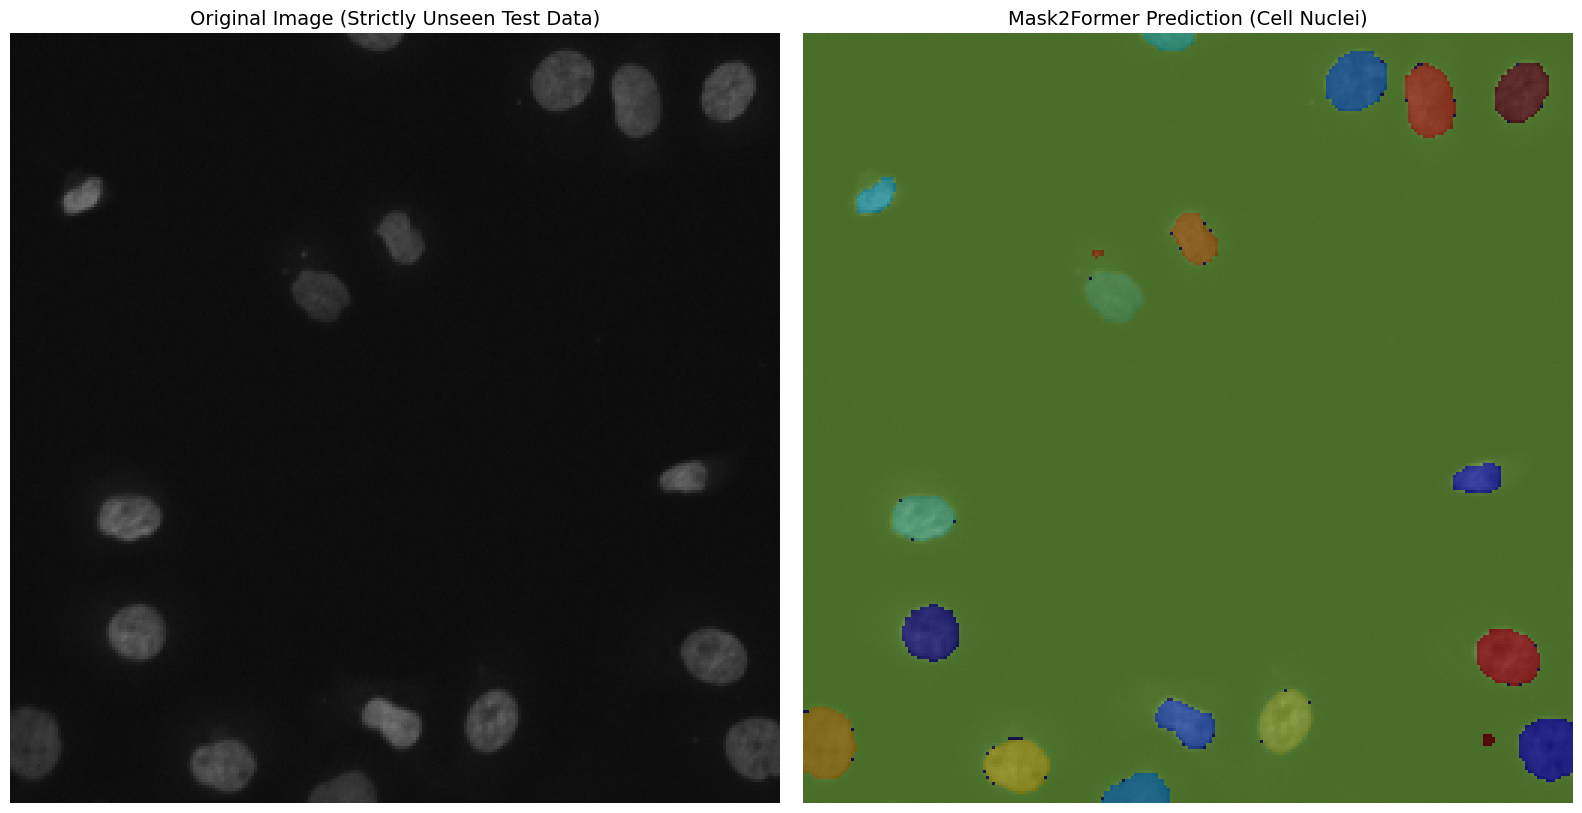

✅ Model successfully found 20 cells in this unseen test image!


In [17]:
# ==========================================
#  فاز چهارم: تست مدل روی داده‌های تست (Test Dataset)
# ==========================================
import random

print("\n🎨 Loading a strictly UNSEEN test image from the Test set...")
model.eval()

# انتخاب یک عکس از 10 درصد دیتای تست (که در هیچ مرحله‌ای از آموزش یا انتخاب مدل دخالت نداشته است)
sample_idx = random.randint(0, len(test_dataset) - 1)
original_idx = test_dataset.indices[sample_idx]

test_folder = full_dataset.folders[original_idx] 
img_path = os.path.join(full_dataset.data_dir, test_folder, 'images', test_folder + '.png')

original_image = cv2.imread(img_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

print(f"🔍 Running Mask2Former Prediction on {test_folder}...")
inputs = processor(images=original_image, return_tensors="pt").to(model.device)

with torch.no_grad():
    outputs = model(**inputs)

target_sizes = [original_image.shape[:2]]
results = processor.post_process_instance_segmentation(
    outputs,
    target_sizes=target_sizes,
    threshold=0.5
)[0]

predicted_mask = results["segmentation"].cpu().numpy()

# رسم تصاویر
fig, axs = plt.subplots(1, 2, figsize=(16, 8))

axs[0].imshow(original_image)
axs[0].set_title("Original Image (Strictly Unseen Test Data)", fontsize=14)
axs[0].axis("off")

axs[1].imshow(original_image)
mask_overlay = axs[1].imshow(predicted_mask, cmap="jet", alpha=0.4)
axs[1].set_title("Mask2Former Prediction (Cell Nuclei)", fontsize=14)
axs[1].axis("off")

plt.tight_layout()
plt.show()

found_cells = len(np.unique(predicted_mask)) - 1
print(f"✅ Model successfully found {found_cells} cells in this unseen test image!")

In [21]:
# ==========================================
# فاز پنجم: ارزیابی علمی (Scientific Evaluation) روی Test Dataset
# محاسبه متریک‌های DICE Score و Mean IoU
# ==========================================


print("\n🔬 Phase 5: Scientific Evaluation on Strict Test Dataset...")
model.eval()

total_dice = 0.0
total_iou = 0.0
num_samples = len(test_dataset)

# خاموش کردن محاسبه گرادیان برای سرعت و مصرف کمتر رم
with torch.no_grad():
    for i in tqdm(range(num_samples), desc="Evaluating Test Data"):
        # 1. استخراج داده‌ها از گاوصندوق (Test Dataset)
        sample = test_dataset[i]
        
        # 2. ساخت ماسکِ واقعی (Ground Truth)
        # ماسک‌ها در دیتاست به صورت لایه‌لایه (هر سلول یک لایه) هستند
        # ما همه را روی هم میندازیم تا یک ماسک کلی باینری (سلول=1، پس‌زمینه=0) بسازیم
        gt_masks = sample["mask_labels"]
        gt_binary = torch.clamp(torch.sum(gt_masks, dim=0), 0, 1).cpu().numpy()
        
        # 3. آماده‌سازی تصویر برای مدل
        pixel_values = sample["pixel_values"].unsqueeze(0).to(model.device)
        
        # 4. پیش‌بینی توسط Mask2Former
        outputs = model(pixel_values=pixel_values)
        
        # 5. استخراج ماسک‌های پیش‌بینی‌شده (Predicted Mask)
        target_sizes = [gt_binary.shape]
        results = processor.post_process_instance_segmentation(
            outputs,
            target_sizes=target_sizes,
            threshold=0.5
        )[0]
        
        pred_instances = results["segmentation"].cpu().numpy()
        # تبدیل شماره سلول‌ها به ماسک باینری (سلول=1، پس‌زمینه=0)
        pred_binary = (pred_instances > 0).astype(np.uint8)
        
        # 6. محاسبه تقاطع (Intersection) و اجتماع (Union) پیکسل‌ها
        intersection = np.logical_and(gt_binary, pred_binary).sum()
        union = np.logical_or(gt_binary, pred_binary).sum()
        
        # 7. فرمول‌های ریاضی IoU و DICE
        if union == 0:
            # جلوگیری از خطای تقسیم بر صفر برای عکس‌های کاملاً سیاه
            iou = 1.0 if np.sum(gt_binary) == 0 and np.sum(pred_binary) == 0 else 0.0
            dice = 1.0 if np.sum(gt_binary) == 0 and np.sum(pred_binary) == 0 else 0.0
        else:
            iou = intersection / union
            dice = 2.0 * intersection / (np.sum(gt_binary) + np.sum(pred_binary))
            
        total_iou += iou
        total_dice += dice

# 8. محاسبه میانگین کل (Mean)
avg_iou = total_iou / num_samples
avg_dice = total_dice / num_samples

print("\n" + "="*50)
print("🏆 FINAL TEST DATASET METRICS 🏆")
print("="*50)
print(f"🔹 Mean IoU (Jaccard Index) : {avg_iou:.4f}")
print(f"🔹 Mean DICE Score (F1)    : {avg_dice:.4f}")
print("="*50)


🔬 Phase 5: Scientific Evaluation on Strict Test Dataset...


Evaluating Test Data: 100%|██████████| 67/67 [00:11<00:00,  5.60it/s]


🏆 FINAL TEST DATASET METRICS 🏆
🔹 Mean IoU (Jaccard Index) : 0.9673
🔹 Mean DICE Score (F1)    : 0.9760
